# Customer Churn: Data Quality Audit and Exploratory Analysis

**Author:** Karan Singh Shekhawat

**Track:** Data Analytics | **Level:** Beginner-friendly | **Task:** EdVyro, *Data Quality and Exploratory Analysis*
**Dataset:** `customer_churn_sample.csv` (synthetic customer records supplied by EdVyro)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

---

## Objective
Audit and clean a customer churn dataset, document every quality decision, and identify the first meaningful patterns related to churn.

## How this notebook maps to the EdVyro passing checklist

| EdVyro checklist item | Where it is covered |
|---|---|
| Profile columns, data types, missing values, outliers and duplicates | Sections 1 to 4 |
| Clean the data with documented assumptions and validation checks | Sections 5 to 7 |
| Calculate summary statistics and inspect meaningful distributions | Sections 8 and 9 |
| Put the work and a short explanation in one public or view-only link | This notebook, plus the exported files listed in Section 12 |
| *Optional upgrade:* export the clean dataset and a data dictionary | Section 12 |

## Contents
1. Setup and dataset overview
2. Missing values
3. Duplicate records
4. Outlier detection
5. Inconsistent or incorrect values
6. Data cleaning (with change log)
7. Assumptions and validation checks
8. Descriptive statistics
9. Exploratory data analysis (visualizations)
10. Patterns related to churn
11. Conclusion, recommendations and limitations
12. Exports (clean dataset and data dictionary)

## 1. Setup and Dataset Overview

In [1]:
import glob
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

# Display and plotting configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

CHURN_PALETTE = {"No": "#4C78A8", "Yes": "#E45756"}   # blue = retained, red = churned

# Output folders (created next to the notebook)
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to outputs/figures so it can be reused in a report."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# Locate and load the dataset. Two reads are used on purpose:
#   raw     -> pandas' normal type inference (what an analyst would see by default)
#   raw_str -> everything as text, with NA-parsing switched off, so hidden blanks,
#              placeholder tokens or stray spaces cannot be silently converted away.
candidates = sorted(glob.glob("customer_churn_sample*.csv")) + [
    "/mnt/user-data/uploads/customer_churn_sample__2_.csv"
]
DATA_PATH = next((p for p in candidates if Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place customer_churn_sample.csv in the same folder as this notebook.")

raw = pd.read_csv(DATA_PATH)
raw_str = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f"Loaded: {Path(DATA_PATH).name}")

# Column groups used throughout the notebook
ID_COL = "CustomerID"
TARGET = "Churn"
NUM_COLS = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
CAT_COLS = ["Gender", "SubscriptionType", "ContractType", "PaymentMethod"]

Loaded: customer_churn_sample.csv


In [3]:
print(f"Rows: {raw.shape[0]}   |   Columns: {raw.shape[1]}\n")

overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "unique_values": raw.nunique(),
    "example": raw.iloc[0],
})
display(overview)

Rows: 15   |   Columns: 11



,dtype,non_null,unique_values,example
CustomerID,str,15,15,CUST-1001
Gender,str,15,2,Female
Age,int64,15,15,34
TenureMonths,int64,15,15,12
SubscriptionType,str,15,3,Basic
MonthlyCharges,float64,15,3,49.99
TotalCharges,float64,15,15,599.88
ContractType,str,15,3,Month-to-Month
SupportTickets,int64,15,7,3
PaymentMethod,str,15,4,Credit Card


In [4]:
print("First 5 rows:")
display(raw.head())
print("Technical info:")
raw.info()

First 5 rows:


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,"1,919.76",One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,"5,399.64",Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


Technical info:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     str    
 1   Gender            15 non-null     str    
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     str    
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     str    
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     str    
 10  Churn             15 non-null     str    
dtypes: float64(2), int64(3), str(6)
memory usage: 1.4 KB


**Column roles**

| Column | Role | Meaning |
|---|---|---|
| `CustomerID` | Identifier | Unique customer key (`CUST-####`) |
| `Gender` | Categorical | Male / Female |
| `Age` | Numeric | Customer age in years |
| `TenureMonths` | Numeric | Months the customer has been subscribed |
| `SubscriptionType` | Categorical (ordinal) | Basic, Pro, Enterprise |
| `MonthlyCharges` | Numeric | Monthly subscription fee |
| `TotalCharges` | Numeric | Total billed to date |
| `ContractType` | Categorical (ordinal) | Month-to-Month, One Year, Two Year |
| `SupportTickets` | Numeric (count) | Support tickets raised |
| `PaymentMethod` | Categorical | Credit Card, Debit Card, UPI, Bank Transfer |
| `Churn` | **Target** | Yes = customer churned, No = retained |

The data types Pandas inferred match these roles: the five numeric columns were parsed as numbers and the text columns as strings.

## 2. Missing Values

Two checks are run: (a) true `NaN` values, and (b) *disguised* missing values such as empty strings, `N/A`, `null`, `?` or `-`, which Pandas would otherwise treat as ordinary text.

In [5]:
missing = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_pct": raw.isna().mean() * 100,
})
display(missing)

# Disguised missing values (checked on the all-text copy)
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "?", "-", "--", "unknown"}
placeholder_hits = raw_str.apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS)).sum()

print(f"Total NaN cells                    : {int(raw.isna().sum().sum())}")
print(f"Total placeholder / blank-text cells: {int(placeholder_hits.sum())}")
print(f"Rows with at least one missing value: {int(raw.isna().any(axis=1).sum())}")

,missing_count,missing_pct
CustomerID,0,0.00
Gender,0,0.00
Age,0,0.00
TenureMonths,0,0.00
SubscriptionType,0,0.00
MonthlyCharges,0,0.00
TotalCharges,0,0.00
ContractType,0,0.00
SupportTickets,0,0.00
PaymentMethod,0,0.00


Total NaN cells                    : 0
Total placeholder / blank-text cells: 0
Rows with at least one missing value: 0


## 3. Duplicate Records

Three definitions of "duplicate" are tested: an identical full row, a repeated `CustomerID`, and identical content under *different* IDs (which would indicate the same customer entered twice).

In [6]:
n_full_dup = int(raw.duplicated().sum())
n_id_dup = int(raw[ID_COL].duplicated().sum())
n_content_dup = int(raw.drop(columns=ID_COL).duplicated().sum())

dup_summary = pd.DataFrame({
    "check": ["Fully identical rows", "Repeated CustomerID", "Same attributes under a different CustomerID"],
    "duplicates_found": [n_full_dup, n_id_dup, n_content_dup],
})
display(dup_summary)

,check,duplicates_found
0,Fully identical rows,0
1,Repeated CustomerID,0
2,Same attributes under a different CustomerID,0


## 4. Outlier Detection

Two complementary methods are applied to every numeric column:

* **IQR rule** — a value is flagged if it lies below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR`.
* **Z-score** — a value is flagged if `|z| > 3`.

> With only 15 rows, a z-score above 3 is mathematically hard to reach (the maximum possible |z| for n = 15 is about 3.6), so the IQR rule is the more informative of the two here. Both are reported for completeness.

In [7]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


rows = []
for c in NUM_COLS:
    s = raw[c]
    lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std(ddof=0)
    rows.append({
        "column": c,
        "min": s.min(), "max": s.max(),
        "IQR_lower_fence": lo, "IQR_upper_fence": hi,
        "iqr_outliers": int(((s < lo) | (s > hi)).sum()),
        "zscore_outliers(|z|>3)": int((z.abs() > 3).sum()),
        "max_|z|": z.abs().max(),
    })
outlier_table = pd.DataFrame(rows).set_index("column")
display(outlier_table)

,min,max,IQR_lower_fence,IQR_upper_fence,iqr_outliers,zscore_outliers(|z|>3),max_|z|
column,,,,,,,
Age,23.00,60.00,4.50,72.50,0,0,1.90
TenureMonths,2.00,48.00,-23.00,57.00,0,0,2.11
MonthlyCharges,49.99,149.99,-47.51,212.49,0,0,1.58
TotalCharges,99.98,"7,199.52","-3,689.82","7,349.46",0,0,2.20
SupportTickets,0.00,6.00,-3.50,8.50,0,0,1.87


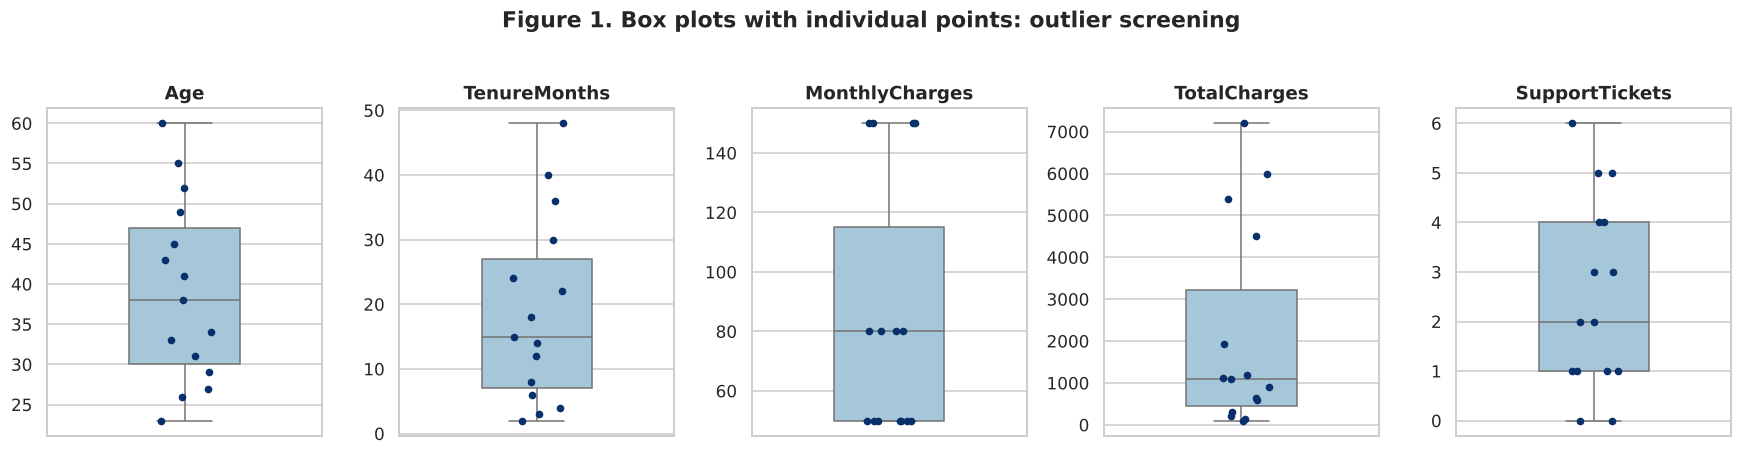

In [8]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(16, 4))
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(y=raw[c], ax=ax, color="#9ecae1", width=0.4)
    sns.stripplot(y=raw[c], ax=ax, color="#08306b", size=5, jitter=0.1)
    ax.set_title(c)
    ax.set_ylabel("")
fig.suptitle("Figure 1. Box plots with individual points: outlier screening", y=1.03, fontweight="bold")
plt.tight_layout()
save_fig(fig, "01_outlier_boxplots")
plt.show()

In [9]:
total_outliers = int(outlier_table["iqr_outliers"].sum())
if total_outliers == 0:
    print("Result: no IQR or z-score outliers in any numeric column.")
    print("The right-skewed TotalCharges values (up to the maximum) are explained by long-tenure,")
    print("high-price customers (see the reconciliation check in Section 5), so they are genuine.")
else:
    print(f"Result: {total_outliers} IQR outlier(s) flagged. Review them below:")
    for c in NUM_COLS:
        lo, hi = iqr_bounds(raw[c])
        flagged = raw[(raw[c] < lo) | (raw[c] > hi)]
        if len(flagged):
            display(flagged)

Result: no IQR or z-score outliers in any numeric column.
The right-skewed TotalCharges values (up to the maximum) are explained by long-tenure,
high-price customers (see the reconciliation check in Section 5), so they are genuine.


## 5. Inconsistent or Incorrect Values

This section goes beyond missing values and duplicates and tests whether each value is *valid* and whether columns agree with each other. Every rule below is explicit, so a reviewer can see exactly what was tested.

| Group | Rules |
|---|---|
| Formatting | No leading/trailing spaces; consistent capitalization and spelling of labels |
| Domain | Only allowed categories; `CustomerID` matches `CUST-####` |
| Range | Age 18–100; tenure ≥ 0; support tickets ≥ 0 and whole numbers; charges > 0 |
| Cross-column | `TotalCharges ≈ TenureMonths × MonthlyCharges`; one fixed price per subscription tier |

In [10]:
ALLOWED = {
    "Gender": ["Female", "Male"],
    "SubscriptionType": ["Basic", "Pro", "Enterprise"],
    "ContractType": ["Month-to-Month", "One Year", "Two Year"],
    "PaymentMethod": ["Credit Card", "Debit Card", "UPI", "Bank Transfer"],
    "Churn": ["Yes", "No"],
}
text_cols = [ID_COL] + CAT_COLS + [TARGET]

checks = []


def add_check(name, rule, violating_mask):
    n = int(pd.Series(violating_mask).sum())
    checks.append({"check": name, "rule": rule, "violations": n,
                   "status": "PASS" if n == 0 else "FLAG"})


# 5a. Formatting
ws_mask = pd.concat([raw_str[c] != raw_str[c].str.strip() for c in text_cols], axis=1).any(axis=1)
add_check("Whitespace", "No text value has leading/trailing spaces", ws_mask)

# 5b. Domain: allowed labels (case-sensitive, so 'yes' or 'UPI ' would be caught)
for col, allowed in ALLOWED.items():
    add_check(f"{col} labels", f"Value in {allowed}", ~raw[col].isin(allowed))

add_check("CustomerID format", "Matches CUST-####", ~raw[ID_COL].str.match(r"^CUST-\d{4}$"))
add_check("CustomerID unique", "No repeated ID", raw[ID_COL].duplicated(keep=False))

# 5c. Ranges
add_check("Age range", "18 <= Age <= 100", ~raw["Age"].between(18, 100))
add_check("Tenure range", "TenureMonths >= 0", raw["TenureMonths"] < 0)
add_check("Support tickets range", "SupportTickets >= 0", raw["SupportTickets"] < 0)
add_check("Whole-number counts", "Age, Tenure, Tickets have no decimals",
          (raw[["Age", "TenureMonths", "SupportTickets"]] % 1 != 0).any(axis=1))
add_check("Charges positive", "MonthlyCharges > 0 and TotalCharges > 0",
          (raw["MonthlyCharges"] <= 0) | (raw["TotalCharges"] <= 0))

# 5d. Cross-column consistency
expected_total = (raw["TenureMonths"] * raw["MonthlyCharges"]).round(2)
total_diff = (raw["TotalCharges"] - expected_total).abs()
add_check("TotalCharges reconciliation", "|TotalCharges - Tenure x MonthlyCharges| <= 0.01", total_diff > 0.01)
add_check("TotalCharges >= MonthlyCharges", "Tenure >= 1 implies at least one month billed",
          (raw["TenureMonths"] >= 1) & (raw["TotalCharges"] < raw["MonthlyCharges"]))
price_variants = raw.groupby("SubscriptionType")["MonthlyCharges"].nunique()
add_check("One price per tier", "Each subscription tier has a single MonthlyCharges value",
          raw["SubscriptionType"].map(price_variants) > 1)

checks_df = pd.DataFrame(checks)
with pd.option_context("display.max_colwidth", None):
    display(checks_df)
print(f"\nChecks run: {len(checks_df)}   |   Failed: {(checks_df['status'] == 'FLAG').sum()}   |   "
      f"Total violations: {checks_df['violations'].sum()}")

,check,rule,violations,status
0,Whitespace,No text value has leading/trailing spaces,0,PASS
1,Gender labels,"Value in ['Female', 'Male']",0,PASS
2,SubscriptionType labels,"Value in ['Basic', 'Pro', 'Enterprise']",0,PASS
3,ContractType labels,"Value in ['Month-to-Month', 'One Year', 'Two Year']",0,PASS
4,PaymentMethod labels,"Value in ['Credit Card', 'Debit Card', 'UPI', 'Bank Transfer']",0,PASS
5,Churn labels,"Value in ['Yes', 'No']",0,PASS
6,CustomerID format,Matches CUST-####,0,PASS
7,CustomerID unique,No repeated ID,0,PASS
8,Age range,18 <= Age <= 100,0,PASS
9,Tenure range,TenureMonths >= 0,0,PASS



Checks run: 16   |   Failed: 0   |   Total violations: 0


In [11]:
# Supporting evidence for the cross-column checks
print("Price per subscription tier (unique MonthlyCharges values):")
display(raw.groupby("SubscriptionType")["MonthlyCharges"].unique().to_frame("unique_monthly_charges"))

print("Largest absolute gap between recorded and recomputed TotalCharges:",
      round(float(total_diff.max()), 4))

print("\nLabel frequencies for every categorical column (to eyeball spelling variants):")
for col in CAT_COLS + [TARGET]:
    print(f"  {col:17s}", raw[col].value_counts().to_dict())

Price per subscription tier (unique MonthlyCharges values):


,unique_monthly_charges
SubscriptionType,
Basic,[49.99]
Enterprise,[149.99]
Pro,[79.99]


Largest absolute gap between recorded and recomputed TotalCharges: 0.0

Label frequencies for every categorical column (to eyeball spelling variants):
  Gender            {'Female': 8, 'Male': 7}
  SubscriptionType  {'Basic': 7, 'Pro': 4, 'Enterprise': 4}
  ContractType      {'Month-to-Month': 7, 'One Year': 4, 'Two Year': 4}
  PaymentMethod     {'Credit Card': 6, 'UPI': 4, 'Bank Transfer': 3, 'Debit Card': 2}
  Churn             {'No': 8, 'Yes': 7}


In [12]:
# Data quality scorecard (single-glance summary of Sections 2 to 5)
scorecard = pd.DataFrame([
    ["Missing values (NaN)", int(raw.isna().sum().sum())],
    ["Disguised missing values (blank / N/A / null ...)", int(placeholder_hits.sum())],
    ["Duplicate rows or repeated IDs", n_full_dup + n_id_dup + n_content_dup],
    ["Statistical outliers (IQR rule)", int(outlier_table["iqr_outliers"].sum())],
    ["Inconsistent or incorrect values (Section 5 rules)", int(checks_df["violations"].sum())],
], columns=["Issue type", "Records flagged"])
display(scorecard)

,Issue type,Records flagged
0,Missing values (NaN),0
1,Disguised missing values (blank / N/A / null ...),0
2,Duplicate rows or repeated IDs,0
3,Statistical outliers (IQR rule),0
4,Inconsistent or incorrect values (Section 5 ru...,0


**Audit finding.** The raw file contains **no missing values, no duplicates, no outliers and no rule violations**. This is plausible for a synthetic teaching dataset, and it is a result in its own right: an audit that finds nothing is still an audit, provided the tests were genuinely capable of finding problems. The checks above are written to catch each issue type (case-sensitive label matching, regex IDs, reconciliation of totals, placeholders in an all-text copy of the file), so the clean result is evidence rather than an assumption.

Because nothing needs to be repaired, Section 6 applies only **defensive standardization and feature preparation**, and states plainly that no data values were changed. Nothing is invented or "fixed" just to have something to show.

## 6. Data Cleaning (with Change Log)

The cleaning pipeline is written so it would handle the common problems if they were present (stray spaces, inconsistent case, wrong dtypes, duplicate rows), and it logs **how many rows each step actually changed**. The raw DataFrame is never modified; all work happens on a copy named `clean`.

In [13]:
clean = raw.copy()
cleaning_log = []


def log_step(step, action, columns, rows_changed, rationale):
    cleaning_log.append({"step": step, "action": action, "columns": columns,
                         "rows_changed": int(rows_changed), "rationale": rationale})


# Step 1: trim whitespace in all text columns
changed = pd.Series(False, index=clean.index)
for c in text_cols:
    trimmed = clean[c].astype(str).str.strip()
    changed |= trimmed != clean[c].astype(str)
    clean[c] = trimmed
log_step(1, "Trim leading/trailing whitespace", ", ".join(text_cols), changed.sum(),
         "Stray spaces make identical labels look different when grouping.")

# Step 2: standardize category labels to a single canonical spelling
changed = pd.Series(False, index=clean.index)
for col, allowed in ALLOWED.items():
    lookup = {a.lower(): a for a in allowed}
    mapped = clean[col].str.lower().map(lookup)
    unmapped = mapped.isna()
    if unmapped.any():
        print(f"WARNING: {int(unmapped.sum())} unrecognized value(s) in {col}; left unchanged for manual review.")
    new_vals = mapped.where(~unmapped, clean[col])
    changed |= (new_vals != clean[col])
    clean[col] = new_vals
log_step(2, "Standardize category labels (case / spelling)", ", ".join(ALLOWED), changed.sum(),
         "Ensures one spelling per category. Unknown labels are never silently deleted.")

# Step 3: enforce correct data types
before_num = clean[NUM_COLS].copy()
for c in ["Age", "TenureMonths", "SupportTickets"]:
    clean[c] = pd.to_numeric(clean[c], errors="raise").astype("int64")
for c in ["MonthlyCharges", "TotalCharges"]:
    clean[c] = pd.to_numeric(clean[c], errors="raise").astype("float64").round(2)
changed = (clean[NUM_COLS] != before_num).any(axis=1)
log_step(3, "Enforce dtypes (counts as int, money as float with 2 dp)", ", ".join(NUM_COLS), changed.sum(),
         "Counts are whole numbers and currency is stored to the cent. errors='raise' stops on non-numeric text.")

# Step 4: remove exact duplicate rows
n_before = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)
log_step(4, "Drop exact duplicate rows", "all columns", n_before - len(clean),
         "Duplicates would double-count customers. None were found in Section 3.")

# Step 5: missing values policy
n_missing = int(clean.isna().sum().sum())
log_step(5, "Missing-value handling (no imputation needed)", "all columns", 0,
         f"{n_missing} missing values remain, so nothing was imputed. Inventing values would bias a 15-row sample.")

# Step 6: outlier policy
log_step(6, "Outlier handling (none removed or capped)", "numeric columns", 0,
         "No IQR outliers were found, and extreme TotalCharges values reconcile exactly with tenure x price.")

# Step 7: derived features used for analysis (new columns only; originals untouched)
clean["ChurnFlag"] = (clean["Churn"] == "Yes").astype("int8")
clean["AgeGroup"] = pd.cut(clean["Age"], bins=[17, 29, 39, 49, np.inf],
                           labels=["18-29", "30-39", "40-49", "50+"]).astype(str)
clean["TenureBand"] = pd.cut(clean["TenureMonths"], bins=[0, 6, 12, 24, np.inf],
                             labels=["0-6 mo", "7-12 mo", "13-24 mo", "25+ mo"]).astype(str)
clean["TicketsPerMonth"] = (clean["SupportTickets"] / clean["TenureMonths"]).round(3)
log_step(7, "Add derived columns: ChurnFlag, AgeGroup, TenureBand, TicketsPerMonth",
         "4 new columns", 0,
         "Numeric target for correlation, bands for grouped comparison, and a tenure-adjusted ticket rate "
         "(minimum tenure is 2 months, so no division by zero).")

cleaning_log_df = pd.DataFrame(cleaning_log)
with pd.option_context("display.max_colwidth", None):
    display(cleaning_log_df)

,step,action,columns,rows_changed,rationale
0,1,Trim leading/trailing whitespace,"CustomerID, Gender, SubscriptionType, ContractType, PaymentMethod, Churn",0,Stray spaces make identical labels look different when grouping.
1,2,Standardize category labels (case / spelling),"Gender, SubscriptionType, ContractType, PaymentMethod, Churn",0,Ensures one spelling per category. Unknown labels are never silently deleted.
2,3,"Enforce dtypes (counts as int, money as float with 2 dp)","Age, TenureMonths, MonthlyCharges, TotalCharges, SupportTickets",0,Counts are whole numbers and currency is stored to the cent. errors='raise' stops on non-numeric text.
3,4,Drop exact duplicate rows,all columns,0,Duplicates would double-count customers. None were found in Section 3.
4,5,Missing-value handling (no imputation needed),all columns,0,"0 missing values remain, so nothing was imputed. Inventing values would bias a 15-row sample."
5,6,Outlier handling (none removed or capped),numeric columns,0,"No IQR outliers were found, and extreme TotalCharges values reconcile exactly with tenure x price."
6,7,"Add derived columns: ChurnFlag, AgeGroup, TenureBand, TicketsPerMonth",4 new columns,0,"Numeric target for correlation, bands for grouped comparison, and a tenure-adjusted ticket rate (minimum tenure is 2 months, so no division by zero)."


In [14]:
print(f"Shape before cleaning: {raw.shape}   ->   after cleaning: {clean.shape}")
print("(Extra columns are the 4 derived features; no original rows or values were removed.)\n")
display(pd.DataFrame({"raw_dtype": raw.dtypes.astype(str),
                      "clean_dtype": clean.dtypes.astype(str)}).fillna("(new column)"))
display(clean.head())

Shape before cleaning: (15, 11)   ->   after cleaning: (15, 15)
(Extra columns are the 4 derived features; no original rows or values were removed.)



,raw_dtype,clean_dtype
Age,int64,int64
AgeGroup,(new column),str
Churn,str,str
ChurnFlag,(new column),int8
ContractType,str,str
CustomerID,str,str
Gender,str,str
MonthlyCharges,float64,float64
PaymentMethod,str,str
SubscriptionType,str,str


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn,ChurnFlag,AgeGroup,TenureBand,TicketsPerMonth
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes,1,30-39,7-12 mo,0.25
1,CUST-1002,Male,45,24,Pro,79.99,"1,919.76",One Year,1,Bank Transfer,No,0,40-49,13-24 mo,0.04
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes,1,18-29,0-6 mo,0.83
3,CUST-1004,Male,52,36,Enterprise,149.99,"5,399.64",Two Year,0,Credit Card,No,0,50+,25+ mo,0.00
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes,1,40-49,7-12 mo,0.50


## 7. Assumptions and Validation Checks

### Assumptions
1. **Each row is one unique customer**, identified by `CustomerID`.
2. **`Churn = Yes`** means the customer has left the service; `No` means still active.
3. **`TotalCharges = TenureMonths × MonthlyCharges`** (no discounts, taxes or plan changes). The data satisfies this exactly, so it is used as a consistency check.
4. **Age 18–100** is the valid range for a subscriber (adult account holders).
5. **Prices are fixed per tier** (Basic 49.99, Pro 79.99, Enterprise 149.99), which the data confirms.
6. **Outliers are retained** unless they are demonstrably errors. Statistical extremeness alone is not a reason to delete a legitimate customer.
7. **No imputation** is performed because no values are missing, and the sample (n = 15) is too small to impute reliably anyway.
8. **Derived age and tenure bands** are analyst-defined groupings (documented in the data dictionary) and not part of the source data.
9. **Standard deviation** is the *sample* standard deviation (n − 1), the Pandas default.
10. The dataset is **synthetic**, so findings describe this file and should not be generalized to a real customer base without validation on real data.

### Validation checks
Each check below is an automated test run on the final `clean` DataFrame. The cell stops with an error if any test fails.

In [15]:
validation = []


def check(name, condition, detail=""):
    validation.append({"validation check": name,
                       "result": "PASS" if bool(condition) else "FAIL",
                       "detail": detail})


orig_cols = list(raw.columns)

check("Row count preserved (nothing dropped)", len(clean) == len(raw), f"{len(raw)} -> {len(clean)}")
check("CustomerID is unique and non-null", clean[ID_COL].is_unique and clean[ID_COL].notna().all())
check("No missing values in any column", clean.isna().sum().sum() == 0)
check("No duplicate rows", not clean.duplicated().any())
check("Original columns identical to raw file (no values altered)",
      raw[orig_cols].astype(str).equals(clean[orig_cols].astype(str)))
check("Count columns are integers",
      all(pd.api.types.is_integer_dtype(clean[c]) for c in ["Age", "TenureMonths", "SupportTickets"]))
check("Money columns are floats",
      all(pd.api.types.is_float_dtype(clean[c]) for c in ["MonthlyCharges", "TotalCharges"]))
for col, allowed in ALLOWED.items():
    check(f"{col} only contains {allowed}", clean[col].isin(allowed).all())
check("CustomerID matches CUST-####", clean[ID_COL].str.match(r"^CUST-\d{4}$").all())
check("Age within 18-100", clean["Age"].between(18, 100).all())
check("Tenure and tickets are >= 0", ((clean["TenureMonths"] >= 0) & (clean["SupportTickets"] >= 0)).all())
check("Charges are positive", ((clean["MonthlyCharges"] > 0) & (clean["TotalCharges"] > 0)).all())
check("TotalCharges = Tenure x MonthlyCharges (+/- 0.01)",
      ((clean["TotalCharges"] - clean["TenureMonths"] * clean["MonthlyCharges"]).abs() <= 0.01).all())
check("ChurnFlag agrees with Churn", (clean["ChurnFlag"] == (clean["Churn"] == "Yes").astype(int)).all())
check("Every row has an AgeGroup and TenureBand",
      clean["AgeGroup"].isin(["18-29", "30-39", "40-49", "50+"]).all()
      and clean["TenureBand"].isin(["0-6 mo", "7-12 mo", "13-24 mo", "25+ mo"]).all())
check("Churned + retained = total rows",
      clean["Churn"].value_counts().sum() == len(clean))

validation_df = pd.DataFrame(validation)
with pd.option_context("display.max_colwidth", None):
    display(validation_df)

assert (validation_df["result"] == "PASS").all(), "One or more validation checks FAILED"
print(f"\nAll {len(validation_df)} validation checks passed.")

,validation check,result,detail
0,Row count preserved (nothing dropped),PASS,15 -> 15
1,CustomerID is unique and non-null,PASS,
2,No missing values in any column,PASS,
3,No duplicate rows,PASS,
4,Original columns identical to raw file (no values altered),PASS,
5,Count columns are integers,PASS,
6,Money columns are floats,PASS,
7,"Gender only contains ['Female', 'Male']",PASS,
8,"SubscriptionType only contains ['Basic', 'Pro', 'Enterprise']",PASS,
9,"ContractType only contains ['Month-to-Month', 'One Year', 'Two Year']",PASS,



All 20 validation checks passed.


## 8. Descriptive Statistics

Mean, median, mode and standard deviation are calculated for every numeric column, along with minimum, maximum and skewness for context. When every value is unique (as with `Age`), no mode exists and the table says so rather than reporting an arbitrary value.

In [16]:
def mode_str(s):
    vc = s.value_counts()
    if vc.max() == 1:
        return "none (all values unique)"
    return ", ".join(f"{v:g}" for v in sorted(vc[vc == vc.max()].index))


desc = pd.DataFrame({
    "count": clean[NUM_COLS].count(),
    "mean": clean[NUM_COLS].mean(),
    "median": clean[NUM_COLS].median(),
    "mode": [mode_str(clean[c]) for c in NUM_COLS],
    "std_dev": clean[NUM_COLS].std(ddof=1),
    "min": clean[NUM_COLS].min(),
    "max": clean[NUM_COLS].max(),
    "skewness": clean[NUM_COLS].skew(),
})
display(desc)

,count,mean,median,mode,std_dev,min,max,skewness
Age,15,39.07,38.00,none (all values unique),11.39,23.00,60.00,0.37
TenureMonths,15,18.80,15.00,none (all values unique),14.33,2.00,48.00,0.71
MonthlyCharges,15,84.66,79.99,49.99,42.74,49.99,149.99,0.87
TotalCharges,15,"2,088.48","1,099.78",none (all values unique),"2,407.37",99.98,"7,199.52",1.21
SupportTickets,15,2.53,2.00,1,1.92,0.00,6.00,0.36


In [17]:
# Categorical columns: mode and frequency distribution
cat_summary = pd.DataFrame({
    "unique_values": clean[CAT_COLS + [TARGET]].nunique(),
    "mode": [clean[c].mode().iloc[0] for c in CAT_COLS + [TARGET]],
    "mode_count": [clean[c].value_counts().iloc[0] for c in CAT_COLS + [TARGET]],
    "mode_share_pct": [clean[c].value_counts(normalize=True).iloc[0] * 100 for c in CAT_COLS + [TARGET]],
})
display(cat_summary)

print("Class balance of the target:")
display(clean["Churn"].value_counts().rename("customers").to_frame()
        .assign(share_pct=lambda d: d["customers"] / d["customers"].sum() * 100))

,unique_values,mode,mode_count,mode_share_pct
Gender,2,Female,8,53.33
SubscriptionType,3,Basic,7,46.67
ContractType,3,Month-to-Month,7,46.67
PaymentMethod,4,Credit Card,6,40.00
Churn,2,No,8,53.33


Class balance of the target:


,customers,share_pct
Churn,,
No,8,53.33
Yes,7,46.67


## 9. Exploratory Data Analysis

With only 15 customers, smooth density curves (KDE) would suggest precision that the data does not have, so histograms are used, and group-level charts are annotated with the actual counts (e.g. `5/7`).

### 9.1 Distributions of numeric variables and target balance

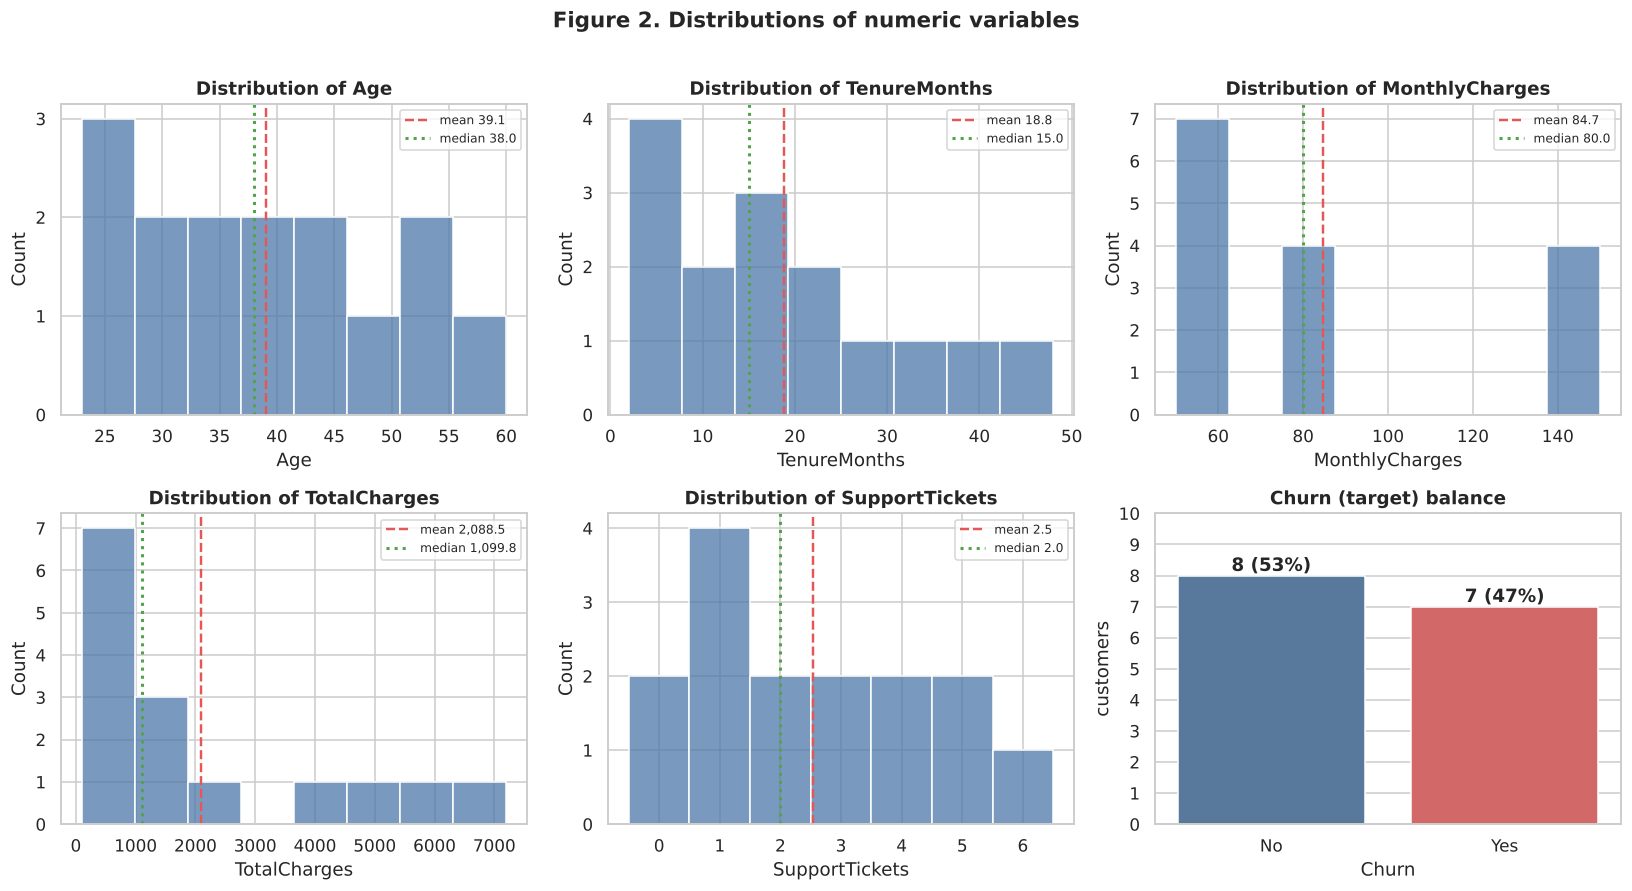

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUM_COLS):
    if col == "SupportTickets":
        sns.histplot(clean[col], discrete=True, ax=ax, color="#4C78A8")
    else:
        sns.histplot(clean[col], bins=8, ax=ax, color="#4C78A8")
    ax.axvline(clean[col].mean(), color="#E45756", ls="--", lw=1.6, label=f"mean {clean[col].mean():,.1f}")
    ax.axvline(clean[col].median(), color="#54A24B", ls=":", lw=2, label=f"median {clean[col].median():,.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=8)

ax = axes.flat[5]
counts = clean["Churn"].value_counts().reindex(["No", "Yes"])
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=CHURN_PALETTE, legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.15, f"{v} ({v / len(clean):.0%})", ha="center", fontweight="bold")
ax.set_title("Churn (target) balance")
ax.set_ylabel("customers")
ax.set_ylim(0, counts.max() + 2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.suptitle("Figure 2. Distributions of numeric variables", y=1.01, fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "02_numeric_distributions")
plt.show()

### 9.2 Customer counts by category, split by churn status

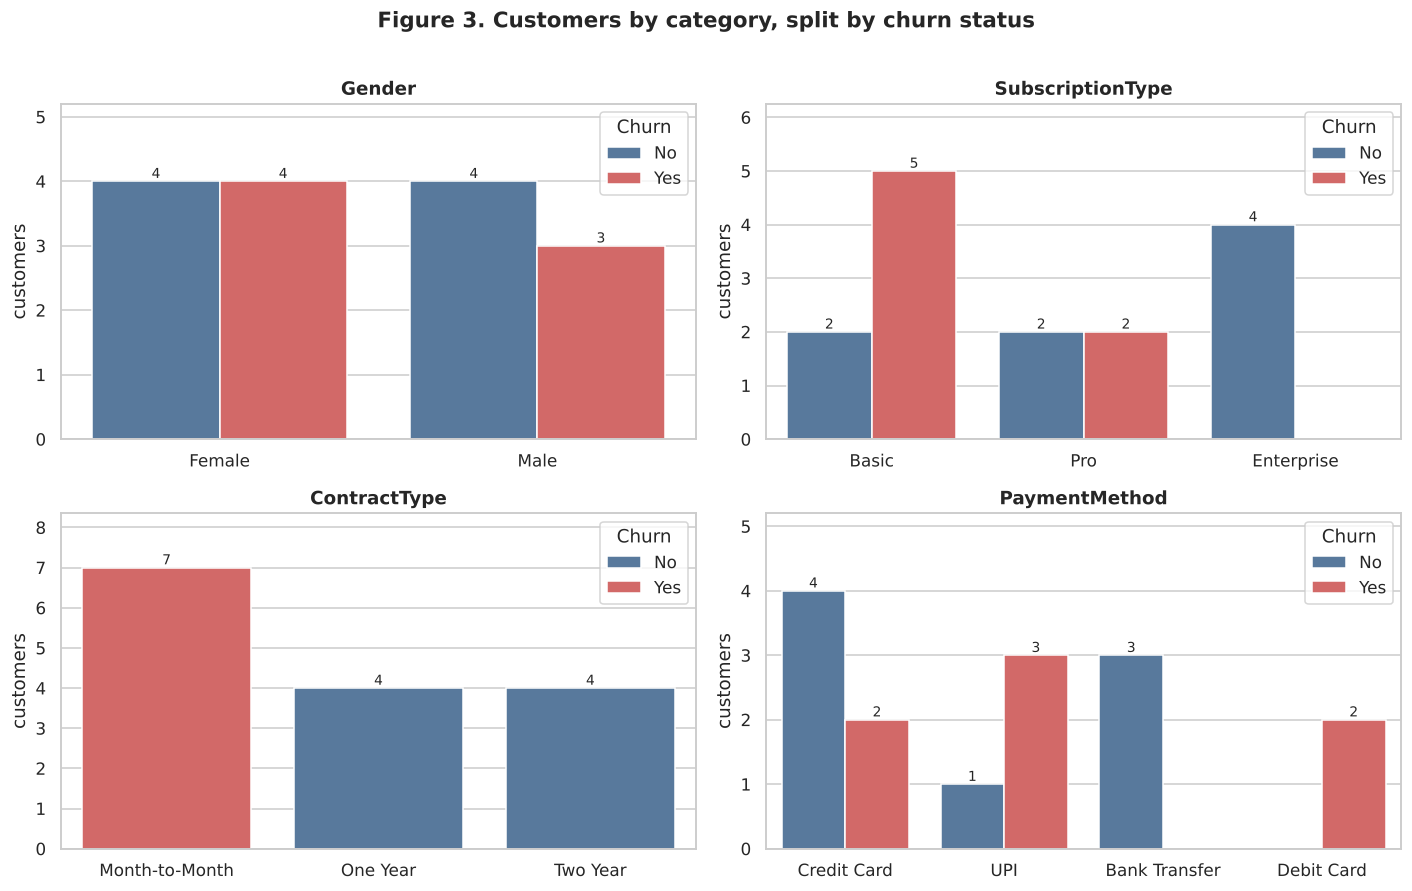

In [19]:
ORDERS = {
    "Gender": ["Female", "Male"],
    "SubscriptionType": ["Basic", "Pro", "Enterprise"],
    "ContractType": ["Month-to-Month", "One Year", "Two Year"],
    "PaymentMethod": list(clean["PaymentMethod"].value_counts().index),
    "AgeGroup": ["18-29", "30-39", "40-49", "50+"],
    "TenureBand": ["0-6 mo", "7-12 mo", "13-24 mo", "25+ mo"],
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, CAT_COLS):
    sns.countplot(data=clean, x=col, order=ORDERS[col], hue="Churn", hue_order=["No", "Yes"],
                  palette=CHURN_PALETTE, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("customers")
    ax.set_ylim(0, ax.get_ylim()[1] + 1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Figure 3. Customers by category, split by churn status", y=1.01, fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "03_category_counts_by_churn")
plt.show()

### 9.3 Churn rate by customer segment
Each bar shows the share of customers in that group who churned. Labels show `churned / group size`, and the dashed line is the overall churn rate.

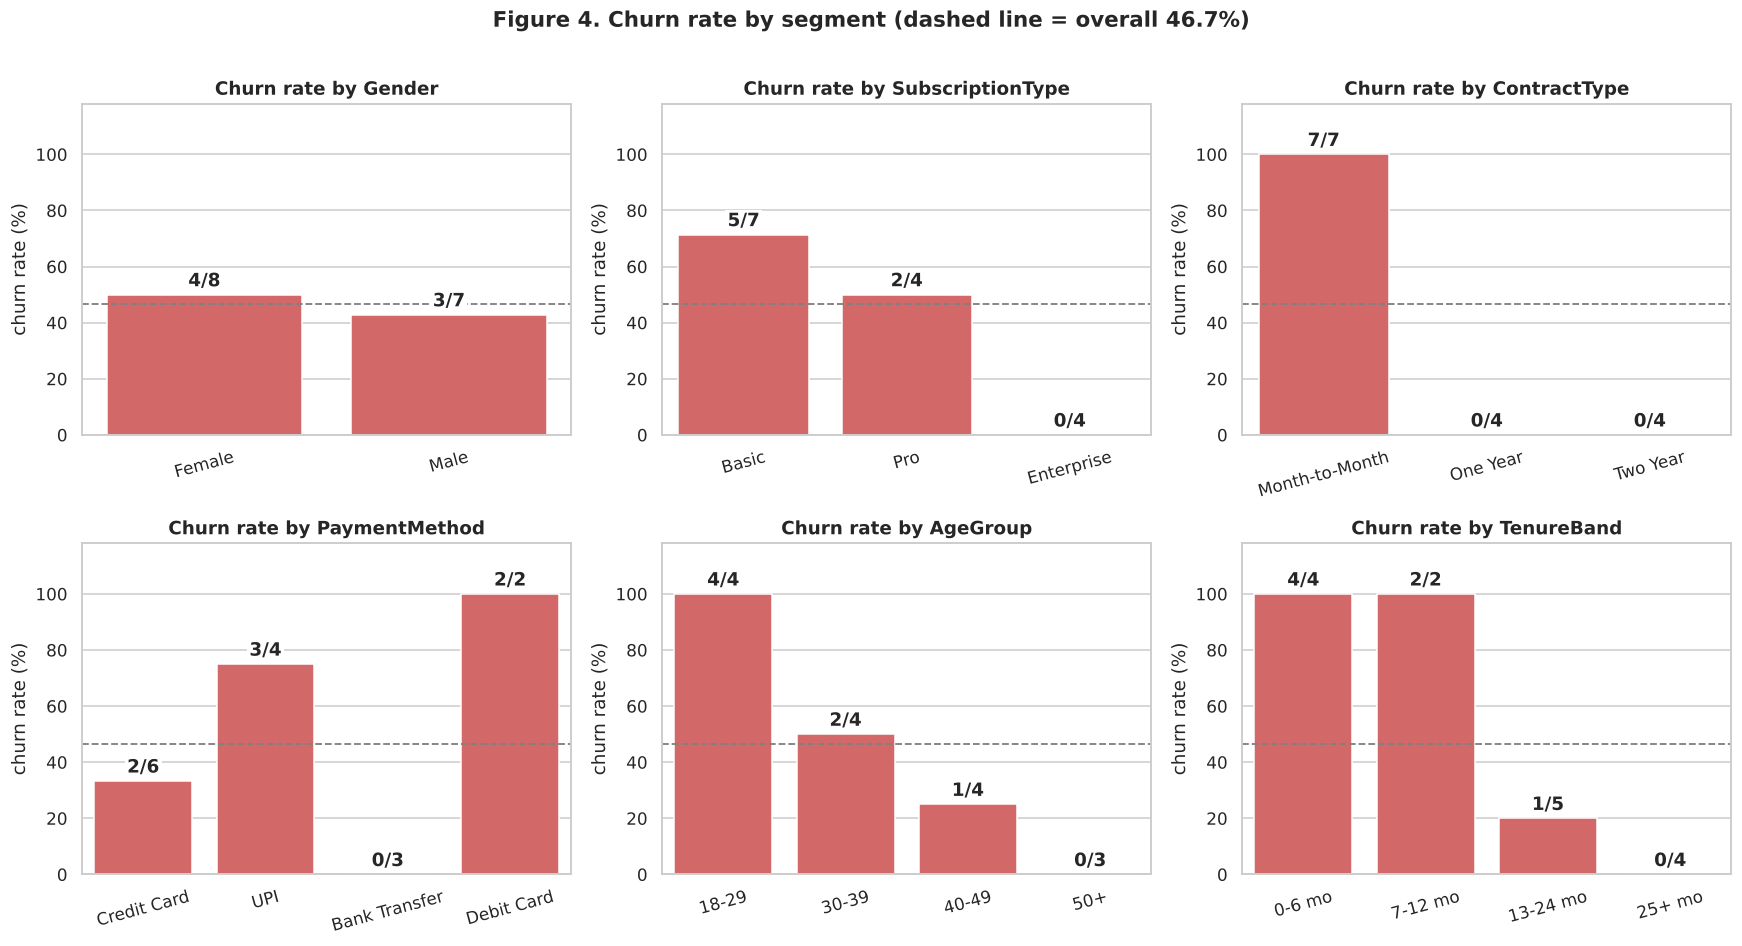

In [20]:
overall_rate = clean["ChurnFlag"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, ORDERS):
    g = (clean.groupby(col)["ChurnFlag"].agg(churned="sum", total="count", rate="mean")
              .reindex(ORDERS[col]))
    sns.barplot(x=g.index, y=g["rate"] * 100, color="#E45756", ax=ax)
    for i, (ch, tot, r) in enumerate(zip(g["churned"], g["total"], g["rate"])):
        ax.text(i, r * 100 + 3, f"{int(ch)}/{int(tot)}", ha="center", fontweight="bold",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.axhline(overall_rate, color="grey", ls="--", lw=1.2)
    ax.set_ylim(0, 118)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("churn rate (%)")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle(f"Figure 4. Churn rate by segment (dashed line = overall {overall_rate:.1f}%)",
             y=1.01, fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "04_churn_rate_by_segment")
plt.show()

### 9.4 Numeric variables compared between churned and retained customers

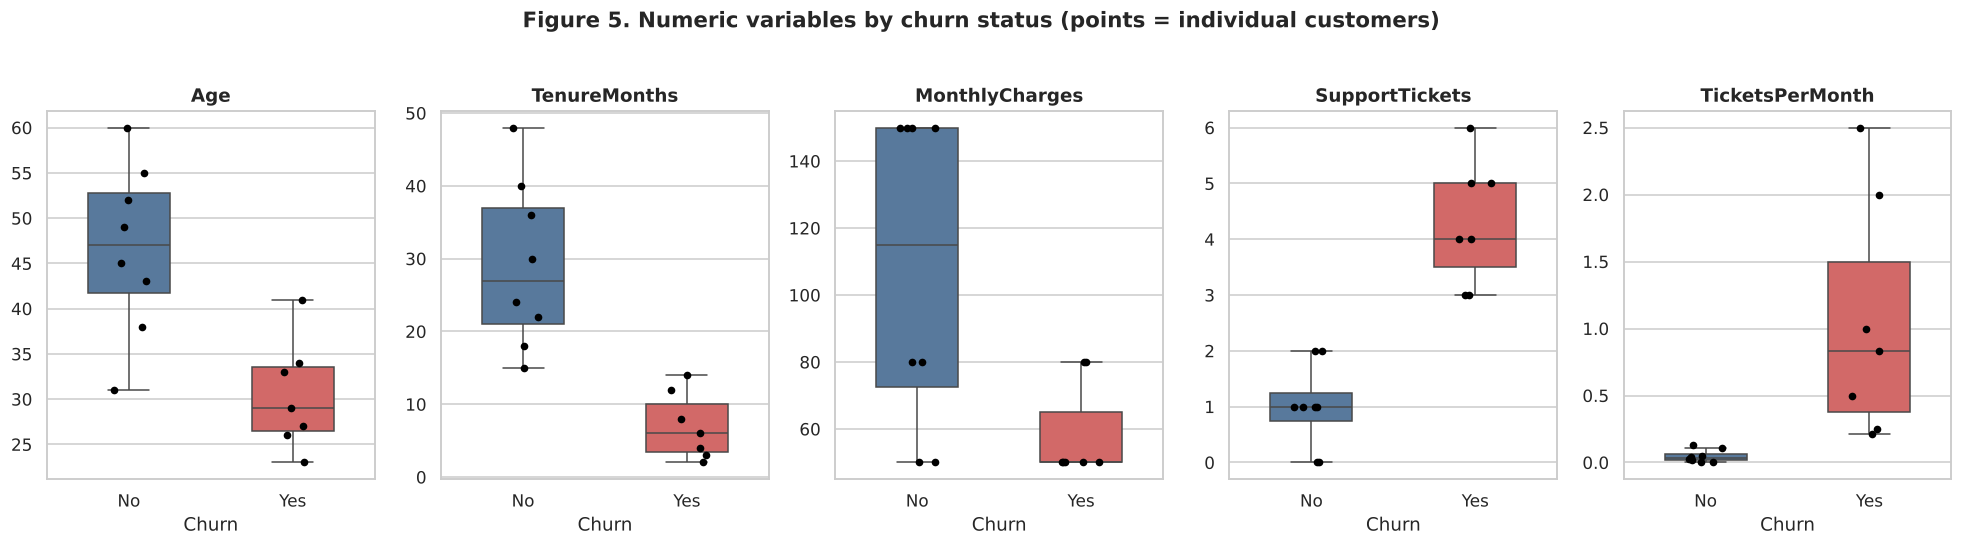

In [21]:
compare_cols = ["Age", "TenureMonths", "MonthlyCharges", "SupportTickets", "TicketsPerMonth"]
fig, axes = plt.subplots(1, len(compare_cols), figsize=(18, 4.8))
for ax, c in zip(axes, compare_cols):
    sns.boxplot(data=clean, x="Churn", y=c, order=["No", "Yes"], hue="Churn", palette=CHURN_PALETTE,
                legend=False, ax=ax, width=0.5, fliersize=0)
    sns.stripplot(data=clean, x="Churn", y=c, order=["No", "Yes"], color="black", size=5, jitter=0.12, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("Churn")
    ax.set_ylabel("")
fig.suptitle("Figure 5. Numeric variables by churn status (points = individual customers)",
             y=1.03, fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "05_numeric_by_churn")
plt.show()

### 9.5 Relationships between variables

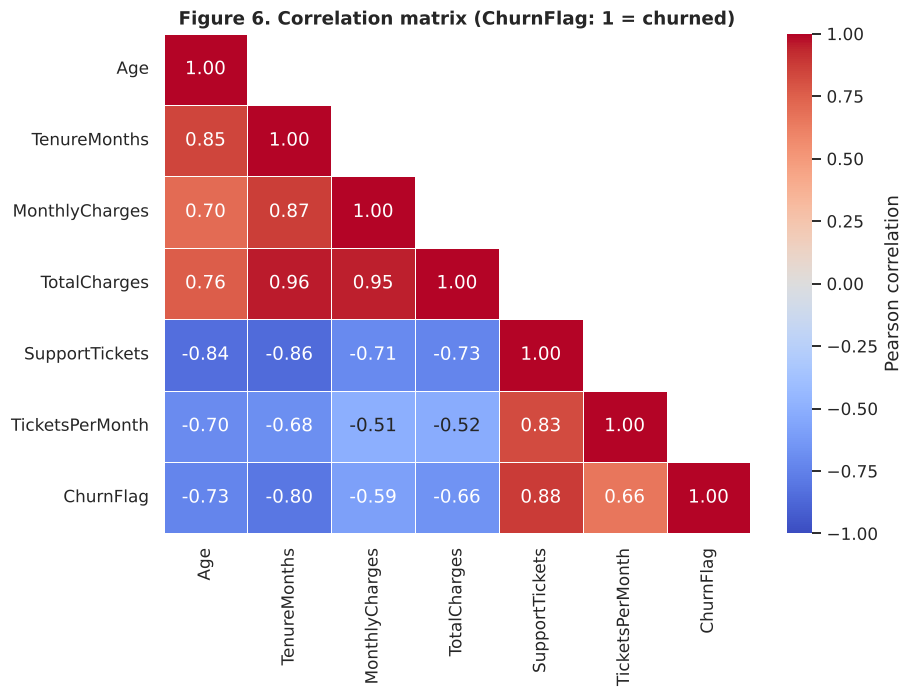

Correlation of each variable with churn:


,correlation_with_churn
TenureMonths,-0.80
Age,-0.73
TotalCharges,-0.66
MonthlyCharges,-0.59
TicketsPerMonth,0.66
SupportTickets,0.88


In [22]:
corr_cols = NUM_COLS + ["TicketsPerMonth", "ChurnFlag"]
corr = clean[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Figure 6. Correlation matrix (ChurnFlag: 1 = churned)")
ax.grid(False)
plt.tight_layout()
save_fig(fig, "06_correlation_heatmap")
plt.show()

print("Correlation of each variable with churn:")
display(corr["ChurnFlag"].drop("ChurnFlag").sort_values().to_frame("correlation_with_churn"))

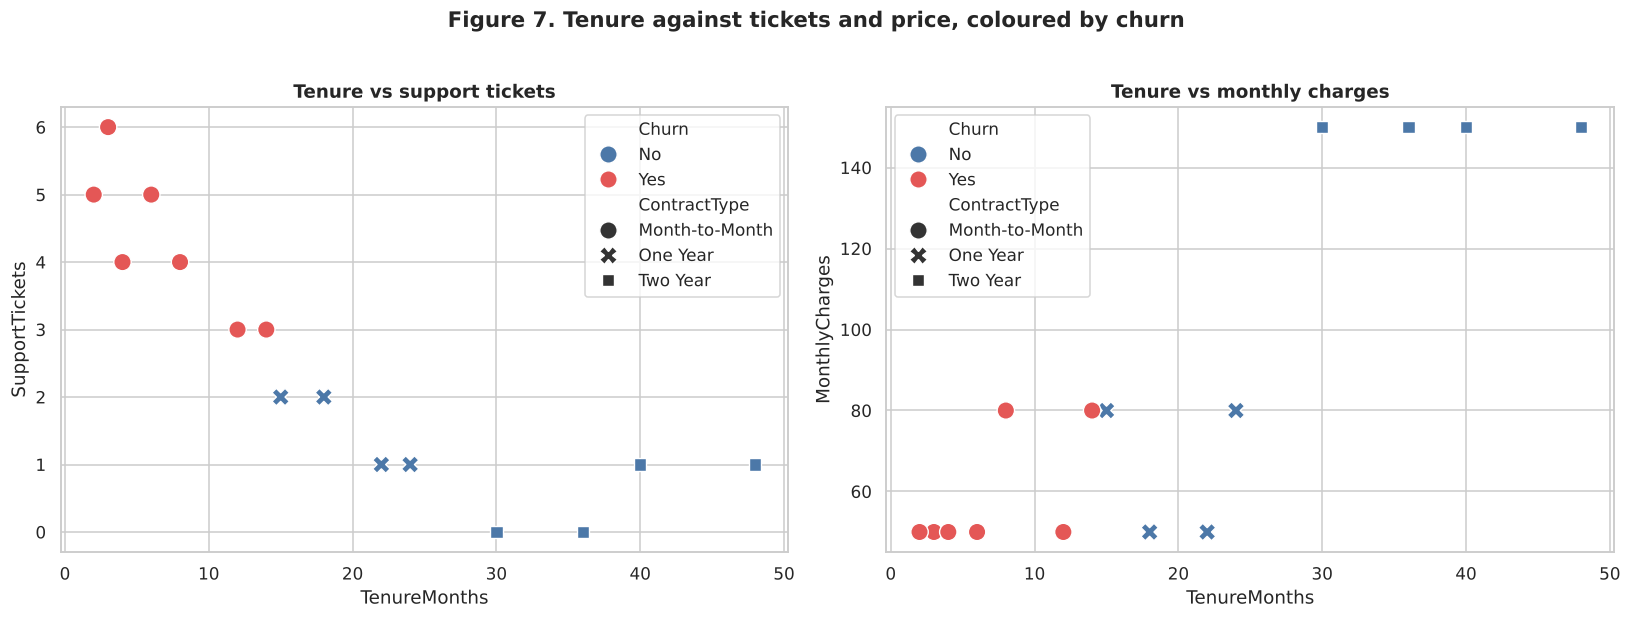

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=clean, x="TenureMonths", y="SupportTickets", hue="Churn", hue_order=["No", "Yes"],
                palette=CHURN_PALETTE, style="ContractType", s=130, ax=axes[0])
axes[0].set_title("Tenure vs support tickets")

sns.scatterplot(data=clean, x="TenureMonths", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"],
                palette=CHURN_PALETTE, style="ContractType", s=130, ax=axes[1])
axes[1].set_title("Tenure vs monthly charges")

fig.suptitle("Figure 7. Tenure against tickets and price, coloured by churn", y=1.02, fontweight="bold", fontsize=14)
plt.tight_layout()
save_fig(fig, "07_tenure_scatter")
plt.show()

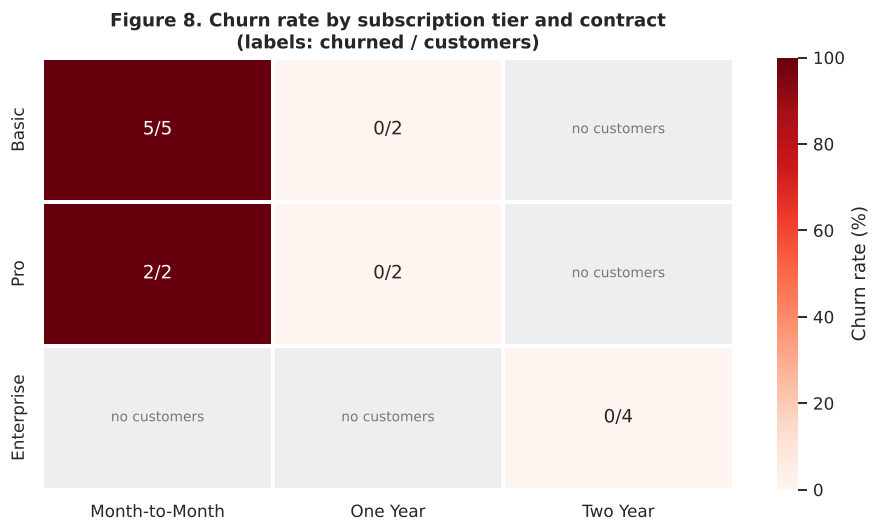

In [24]:
# Subscription tier x contract type: does tier explain churn, or does contract?
grp = clean.groupby(["SubscriptionType", "ContractType"])["ChurnFlag"].agg(churned="sum", total="count")
pivot_rate = (grp["churned"] / grp["total"]).unstack("ContractType") \
    .reindex(index=ORDERS["SubscriptionType"], columns=ORDERS["ContractType"])
labels = (grp["churned"].astype(int).astype(str) + "/" + grp["total"].astype(str)).unstack("ContractType") \
    .reindex(index=ORDERS["SubscriptionType"], columns=ORDERS["ContractType"]).fillna("no customers")

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.heatmap(pivot_rate * 100, annot=labels, fmt="", cmap="Reds", vmin=0, vmax=100, linewidths=1.5,
            linecolor="white", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_facecolor("#EEEEEE")      # empty tier/contract combinations stay grey
ax.grid(False)
for i, tier in enumerate(ORDERS["SubscriptionType"]):
    for j, contract in enumerate(ORDERS["ContractType"]):
        if pd.isna(pivot_rate.loc[tier, contract]):
            ax.text(j + 0.5, i + 0.5, "no customers", ha="center", va="center", color="#777777", fontsize=9)
ax.set_title("Figure 8. Churn rate by subscription tier and contract\n(labels: churned / customers)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
save_fig(fig, "08_tier_by_contract_heatmap")
plt.show()

## 10. Patterns Related to Customer Churn

All numbers below are computed from the cleaned data.

In [25]:
overall = clean["ChurnFlag"].mean()
print(f"Overall churn: {int(clean['ChurnFlag'].sum())} of {len(clean)} customers ({overall:.1%})\n")

# 10.1 Churn rate for every categorical / banded feature
frames = []
for col in ORDERS:
    g = (clean.groupby(col)["ChurnFlag"].agg(customers="count", churned="sum", churn_rate_pct="mean")
              .reindex(ORDERS[col]).reset_index().rename(columns={col: "group"}))
    g["churn_rate_pct"] *= 100
    g.insert(0, "feature", col)
    frames.append(g)
segment_table = pd.concat(frames, ignore_index=True)
display(segment_table)

Overall churn: 7 of 15 customers (46.7%)



,feature,group,customers,churned,churn_rate_pct
0,Gender,Female,8,4,50.00
1,Gender,Male,7,3,42.86
2,SubscriptionType,Basic,7,5,71.43
3,SubscriptionType,Pro,4,2,50.00
4,SubscriptionType,Enterprise,4,0,0.00
5,ContractType,Month-to-Month,7,7,100.00
6,ContractType,One Year,4,0,0.00
7,ContractType,Two Year,4,0,0.00
8,PaymentMethod,Credit Card,6,2,33.33
9,PaymentMethod,UPI,4,3,75.00


In [26]:
# 10.2 Average profile: churned vs retained
profile_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets", "TicketsPerMonth"]
g = clean.groupby("Churn")[profile_cols]
profile = pd.concat([g.mean().T.add_prefix("mean | churn="),
                     g.median().T.add_prefix("median | churn=")], axis=1)
display(profile)

Churn,mean | churn=No,mean | churn=Yes,median | churn=No,median | churn=Yes
Age,46.62,30.43,47.00,29.00
TenureMonths,29.12,7.00,27.00,6.00
MonthlyCharges,107.49,58.56,114.99,49.99
TotalCharges,"3,527.21",444.22,"3,209.73",299.94
SupportTickets,1.00,4.29,1.00,4.00
TicketsPerMonth,0.05,1.04,0.03,0.83


In [27]:
# 10.3 Do churned and retained customers overlap on each numeric variable?
rows = []
for c in ["Age", "TenureMonths", "MonthlyCharges", "SupportTickets", "TicketsPerMonth"]:
    yes, no = clean.loc[clean["Churn"] == "Yes", c], clean.loc[clean["Churn"] == "No", c]
    overlap = max(yes.min(), no.min()) <= min(yes.max(), no.max())
    rows.append({"variable": c,
                 "churned_min": yes.min(), "churned_max": yes.max(),
                 "retained_min": no.min(), "retained_max": no.max(),
                 "ranges_overlap": "Yes" if overlap else "No (clean separation)"})
display(pd.DataFrame(rows).set_index("variable"))

,churned_min,churned_max,retained_min,retained_max,ranges_overlap
variable,,,,,
Age,23.00,41.00,31.00,60.00,Yes
TenureMonths,2.00,14.00,15.00,48.00,No (clean separation)
MonthlyCharges,49.99,79.99,49.99,149.99,Yes
SupportTickets,3.00,6.00,0.00,2.00,No (clean separation)
TicketsPerMonth,0.21,2.50,0.00,0.13,No (clean separation)


In [28]:
# 10.4 Contract type vs churn, and revenue exposure
print("Contract type vs churn (counts):")
display(pd.crosstab(clean["ContractType"], clean["Churn"], margins=True).reindex(ORDERS["ContractType"] + ["All"]))

mrr_total = clean["MonthlyCharges"].sum()
mrr_churned = clean.loc[clean["ChurnFlag"] == 1, "MonthlyCharges"].sum()
print(f"Monthly charges of all customers      : {mrr_total:,.2f}")
print(f"Monthly charges of churned customers  : {mrr_churned:,.2f}  ({mrr_churned / mrr_total:.1%} of monthly billing)")
print(f"Share of customers who churned        : {overall:.1%}")
print(f"Average monthly charge, churned       : {clean.loc[clean['ChurnFlag'] == 1, 'MonthlyCharges'].mean():,.2f}")
print(f"Average monthly charge, retained      : {clean.loc[clean['ChurnFlag'] == 0, 'MonthlyCharges'].mean():,.2f}")

Contract type vs churn (counts):


Churn,No,Yes,All
ContractType,,,
Month-to-Month,0,7,7
One Year,4,0,4
Two Year,4,0,4
All,8,7,15


Monthly charges of all customers      : 1,269.85
Monthly charges of churned customers  : 409.93  (32.3% of monthly billing)
Share of customers who churned        : 46.7%
Average monthly charge, churned       : 58.56
Average monthly charge, retained      : 107.49


## 11. Conclusion, Recommendations and Limitations

### Conclusion

The dataset passed every quality test: 15 customer records and 11 columns with **no missing values, duplicates, outliers or rule violations** (16 audit rules and 20 post-cleaning validation checks, all passing). Cleaning therefore consisted of defensive standardization and the addition of four derived analysis columns; **no original value was changed or removed**.

Seven of the 15 customers (46.7%) churned, and the exploratory analysis shows that churn in this file is strongly structured:

| # | Finding (computed from the data) | Evidence |
|---|---|---|
| 1 | **Contract type separates churn completely.** Every Month-to-Month customer churned; no One-Year or Two-Year customer did. | 7/7 vs 0/8 (Section 10.4, Fig. 4) |
| 2 | **Churn is concentrated in the first year or so.** Every customer with 14 months of tenure or less churned; none with 15 months or more did. | Churned tenure 2–14 vs retained 15–48; mean 7.0 vs 29.1 months (Fig. 5) |
| 3 | **Support tickets are the strongest single warning signal.** Every customer with 3 or more tickets churned; every retained customer had 2 or fewer. | Mean 4.29 vs 1.00 tickets; correlation with churn +0.88 (Fig. 6). Tenure-adjusted: 1.04 vs 0.05 tickets per month |
| 4 | **Younger customers churn more**, but age overlaps between the groups, so it is a weaker signal. | Mean age 30.4 vs 46.6; all 4 customers aged 18–29 churned, none of the 3 aged 50+; ranges 23–41 vs 31–60 overlap |
| 5 | **Subscription tier looks predictive, but it is mostly a contract effect.** Basic churns at 71% and Enterprise at 0%, yet all Enterprise customers are on Two-Year contracts. Within a given contract, tier makes no difference. | Month-to-Month: Basic 5/5 and Pro 2/2 churned. One Year: Basic 0/2 and Pro 0/2 (Fig. 8) |
| 6 | **Gender shows no meaningful difference.** | Female 4/8 (50%) vs Male 3/7 (43%) |
| 7 | **Payment method differs, but the groups are tiny** (2 to 6 customers each) and likely mirror the contract mix. Treat as a hypothesis only. | UPI 3/4, Debit Card 2/2, Credit Card 2/6, Bank Transfer 0/3 |
| 8 | **Churned customers are 47% of customers but 32% of monthly billing**, because they skew toward the cheaper Basic tier. | 409.93 of 1,269.85 monthly charges; average 58.56 vs 107.49 |

### Recommendations (hypotheses to test on real data)
1. **Concentrate retention effort on the first 12 to 14 months** with onboarding and early check-ins, because that is where all churn in this file occurs.
2. **Use support-ticket volume as an early-warning trigger.** In this sample a threshold of 3 tickets flags every churned customer with no false alarms; a real threshold would need to be calibrated on a larger dataset.
3. **Offer incentives to move Month-to-Month customers onto annual contracts**, starting with Basic and Pro customers, since contract commitment is the clearest dividing line.
4. **Investigate why newer customers raise so many tickets** (product friction, onboarding gaps, billing confusion) so the cause can be fixed and not just the symptom monitored.

### Limitations
* **Very small, synthetic sample (n = 15).** The clean separations above (for example 7/7 and 0/8) are unusually perfect and would almost certainly be noisier in real data. Findings illustrate the analytical method and should not be generalized. Formal significance tests would be unreliable at this size and were deliberately not used.
* **Association, not causation.** High ticket counts may be a *symptom* of dissatisfaction rather than its cause, and customers who already intend to leave may choose Month-to-Month contracts.
* **Possible measurement bias.** If `TenureMonths` is the final lifetime for churned customers but still accumulating for active ones, short tenure among churners is partly built into how the data was recorded.
* **Overlapping predictors.** Age, tenure and charges are strongly inter-correlated (for example Age and Tenure r = 0.85), and `TotalCharges` equals tenure × price by construction, so the independent effect of each variable cannot be separated here.
* **Single snapshot.** The file has no dates, so trends over time and the timing of churn cannot be examined.

### Suggested next steps
Validate on a larger real dataset, then build a simple, explainable model (logistic regression or a shallow decision tree) with cross-validation, and use survival analysis to study *when* customers churn.

## 12. Exports: Clean Dataset and Data Dictionary

*(Optional portfolio upgrade from the EdVyro brief.)*

In [29]:
data_dictionary = pd.DataFrame([
    ["CustomerID", "Original", "string", "Unique customer identifier", "Format CUST-####; unique"],
    ["Gender", "Original", "string", "Customer gender", "Female, Male"],
    ["Age", "Original", "int", "Customer age in years", "18 to 100 (observed 23 to 60)"],
    ["TenureMonths", "Original", "int", "Months subscribed", ">= 0 (observed 2 to 48)"],
    ["SubscriptionType", "Original", "string", "Subscription tier", "Basic, Pro, Enterprise"],
    ["MonthlyCharges", "Original", "float", "Monthly fee in currency units", "> 0; fixed per tier (49.99 / 79.99 / 149.99)"],
    ["TotalCharges", "Original", "float", "Total billed to date", "= TenureMonths x MonthlyCharges"],
    ["ContractType", "Original", "string", "Contract commitment", "Month-to-Month, One Year, Two Year"],
    ["SupportTickets", "Original", "int", "Support tickets raised", ">= 0 whole numbers (observed 0 to 6)"],
    ["PaymentMethod", "Original", "string", "Payment channel", "Credit Card, Debit Card, UPI, Bank Transfer"],
    ["Churn", "Original", "string", "Target: did the customer churn?", "Yes, No"],
    ["ChurnFlag", "Derived", "int8", "Numeric version of Churn", "1 = Yes, 0 = No"],
    ["AgeGroup", "Derived", "string", "Age band from Age", "18-29, 30-39, 40-49, 50+"],
    ["TenureBand", "Derived", "string", "Tenure band from TenureMonths", "0-6 mo, 7-12 mo, 13-24 mo, 25+ mo"],
    ["TicketsPerMonth", "Derived", "float", "SupportTickets / TenureMonths (3 dp)", ">= 0"],
], columns=["column", "origin", "type", "description", "valid values / rule"])

# Safety net: dictionary must describe exactly the columns in the exported file
assert list(data_dictionary["column"]) == list(clean.columns), "Dictionary and dataset columns differ"

clean.to_csv(OUT_DIR / "customer_churn_clean.csv", index=False)
data_dictionary.to_csv(OUT_DIR / "data_dictionary.csv", index=False)
cleaning_log_df.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
validation_df.to_csv(OUT_DIR / "validation_results.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(data_dictionary)

print("Files written:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.as_posix())

,column,origin,type,description,valid values / rule
0,CustomerID,Original,string,Unique customer identifier,Format CUST-####; unique
1,Gender,Original,string,Customer gender,"Female, Male"
2,Age,Original,int,Customer age in years,18 to 100 (observed 23 to 60)
3,TenureMonths,Original,int,Months subscribed,>= 0 (observed 2 to 48)
4,SubscriptionType,Original,string,Subscription tier,"Basic, Pro, Enterprise"
5,MonthlyCharges,Original,float,Monthly fee in currency units,> 0; fixed per tier (49.99 / 79.99 / 149.99)
6,TotalCharges,Original,float,Total billed to date,= TenureMonths x MonthlyCharges
7,ContractType,Original,string,Contract commitment,"Month-to-Month, One Year, Two Year"
8,SupportTickets,Original,int,Support tickets raised,>= 0 whole numbers (observed 0 to 6)
9,PaymentMethod,Original,string,Payment channel,"Credit Card, Debit Card, UPI, Bank Transfer"


Files written:
   outputs/cleaning_log.csv
   outputs/customer_churn_clean.csv
   outputs/data_dictionary.csv
   outputs/figures/01_outlier_boxplots.png
   outputs/figures/02_numeric_distributions.png
   outputs/figures/03_category_counts_by_churn.png
   outputs/figures/04_churn_rate_by_segment.png
   outputs/figures/05_numeric_by_churn.png
   outputs/figures/06_correlation_heatmap.png
   outputs/figures/07_tenure_scatter.png
   outputs/figures/08_tier_by_contract_heatmap.png
   outputs/validation_results.csv
